<a href="https://colab.research.google.com/github/dapenuela/Practica_GAN_Colab/blob/main/Practica_GAN_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica de GAN con dígitos manuscritos

Diego Armando Peñuela Cárdenas · Especialización en Inteligencia Artificial

Abre este archivo en Google Colab y ejecuta todas las celdas. Funciona con CPU. Las salidas guardadas corresponden a una ejecución local del mismo código.

El ejercicio adapta las lecturas de Michael Dietz (2017) y Viridiana Romero Martínez (2019) a imágenes de 8 × 8. Usa el conjunto Digits incluido en scikit-learn. El generador recibe ruido y el discriminador compara imágenes reales con sintéticas. Las etiquetas de los dígitos quedan fuera del entrenamiento.

## Datos y entrenamiento

Se alterna una actualización del discriminador con una del generador por lote. La pérdida es entropía cruzada binaria calculada a partir de logits. El generador usa como objetivo que el discriminador clasifique sus imágenes como reales.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

rng = np.random.default_rng(42)
images = load_digits().data.astype(np.float32) / 8 - 1
epochs, batch, latent, rate = 100, 64, 32, 0.001
checkpoints = (0, 1, 25, 100)

def weight(n, m):
    return rng.normal(0, np.sqrt(2 / (n + m)), (n, m)).astype(np.float32)

def model(n, h, m):
    return [weight(n, h), np.zeros(h, np.float32),
            weight(h, m), np.zeros(m, np.float32)]

def forward(x, params, generator=False):
    w1, b1, w2, b2 = params
    pre = x @ w1 + b1
    hidden = np.where(pre > 0, pre, 0.2 * pre)
    out = hidden @ w2 + b2
    return (np.tanh(out) if generator else out), (x, pre, hidden)

def backward(delta, cache, params):
    x, pre, hidden = cache
    dh = (delta @ params[2].T) * np.where(pre > 0, 1.0, 0.2).astype(np.float32)
    return [x.T @ dh, dh.sum(0), hidden.T @ delta, delta.sum(0)], dh @ params[0].T

class Adam:
    def __init__(self, params):
        self.params = params
        self.m = [np.zeros_like(p) for p in params]
        self.v = [np.zeros_like(p) for p in params]
        self.step = 0

    def update(self, grads):
        self.step += 1
        for p, m, v, g in zip(self.params, self.m, self.v, grads):
            m[:] = .9 * m + .1 * g
            v[:] = .999 * v + .001 * g**2
            p -= rate * (m / (1 - .9**self.step)) / (np.sqrt(v / (1 - .999**self.step)) + 1e-8)

def noise(n):
    return rng.standard_normal((n, latent)).astype(np.float32)

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -40, 40)))

G, D = model(latent, 128, 64), model(64, 128, 1)
opt_g, opt_d = Adam(G), Adam(D)
fixed = noise(12)
samples = {0: forward(fixed, G, True)[0]}
history = []

for epoch in range(1, epochs + 1):
    totals = np.zeros(2)
    order = rng.permutation(len(images))
    for start in range(0, len(order), batch):
        real = images[order[start:start + batch]]
        n = len(real)
        fake, _ = forward(noise(n), G, True)
        logits, cache = forward(np.concatenate([real, fake]), D)
        labels = np.concatenate([np.ones((n, 1)), np.zeros((n, 1))]).astype(np.float32)
        loss_d = np.mean(np.logaddexp(0, logits) - labels * logits)
        grads_d, _ = backward((sigmoid(logits) - labels) / (2 * n), cache, D)
        opt_d.update(grads_d)

        fake, cache_g = forward(noise(n), G, True)
        logits, cache_d = forward(fake, D)
        loss_g = np.mean(np.logaddexp(0, -logits))
        _, grad_fake = backward((sigmoid(logits) - 1) / n, cache_d, D)
        grads_g, _ = backward(grad_fake * (1 - fake**2), cache_g, G)
        opt_g.update(grads_g)
        totals += n * np.array([loss_d, loss_g])
    history.append(totals / len(images))
    if epoch in checkpoints:
        samples[epoch] = forward(fixed, G, True)[0]
        print(f'Época {epoch:3d} | D = {history[-1][0]:.4f} | G = {history[-1][1]:.4f}')


Época   1 | D = 0.6386 | G = 0.5187
Época  25 | D = 0.7221 | G = 1.0027
Época 100 | D = 0.7252 | G = 0.9033


## Resultados

Las columnas de las filas sintéticas reutilizan los mismos vectores latentes. La primera fila muestra imágenes reales de referencia sin emparejarlas con las generadas. Las pérdidas se promedian por época ponderando cada lote por su tamaño.

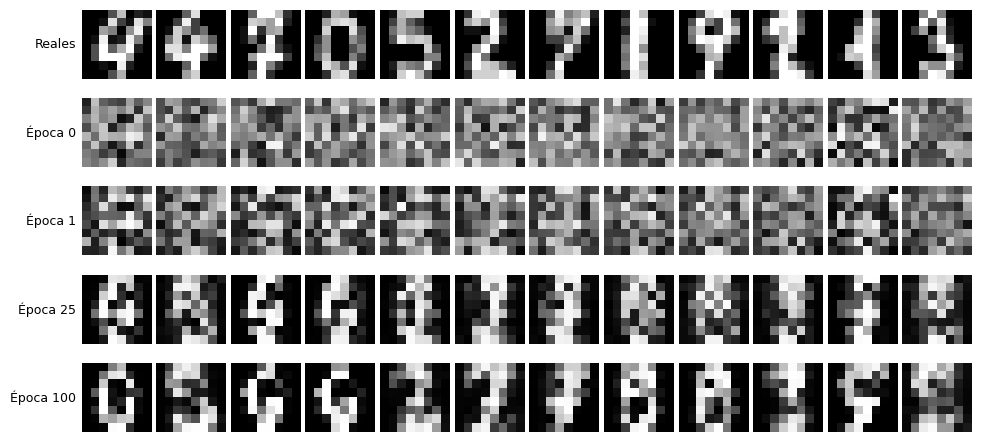

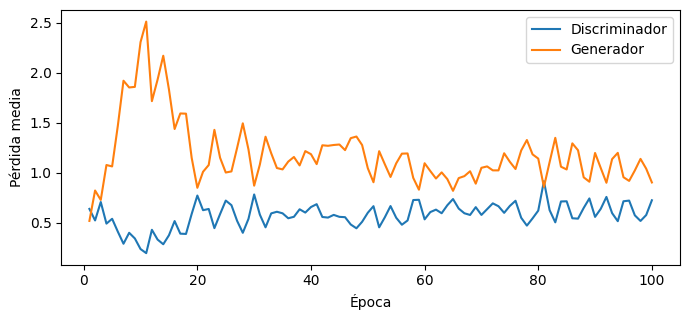

In [2]:
fig, axes = plt.subplots(5, 12, figsize=(10, 4.5))
reference = images[np.random.default_rng(10).choice(len(images), 12, replace=False)]
for row, (label, group) in enumerate([('Reales', reference)] + [(f'Época {e}', samples[e]) for e in checkpoints]):
    for col, ax in enumerate(axes[row]):
        ax.imshow(group[col].reshape(8, 8), cmap='gray', vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if col == 0:
            ax.set_ylabel(label, rotation=0, ha='right', va='center', fontsize=9)
fig.subplots_adjust(left=.10, right=.99, bottom=.02, top=.98, wspace=.08, hspace=.12)
plt.savefig('muestras_gan.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(range(1, epochs + 1), history, label=['Discriminador', 'Generador'])
ax.set(xlabel='Época', ylabel='Pérdida media')
ax.legend()
fig.tight_layout()
plt.savefig('perdidas_gan.png', dpi=160)
plt.show()
